In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import tables as tb
import matplotlib.pyplot as plt
import numpy as np
import glob as glob

from tqdm import tqdm
from scipy.spatial     import cKDTree
from scipy.optimize import curve_fit
from scipy.interpolate import RegularGridInterpolator

import sys
import os

os.chdir('/scratch/pablovzqz/MELT/nb/')
sys.path.insert(0, '/scratch/pablovzqz/MELT/src/')

from core import get_hits, find_path_files
from plotter import plot_deconvolved, plot_light_table
from reco import ML_EM

In [3]:
path = '/scratch/pablovzqz/MELT/data/hits_2clusters.h5'

In [4]:
hits = get_hits(path)

In [5]:
evt = hits[hits.event == hits.event.unique()[0]]

In [6]:
evt.cluster.value_counts()

1    191
0    129
Name: cluster, dtype: int64

Sensor response loaded!!


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 30/30 [01:12<00:00,  2.42s/it]


Sensor response loaded!!


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 30/30 [01:06<00:00,  2.23s/it]


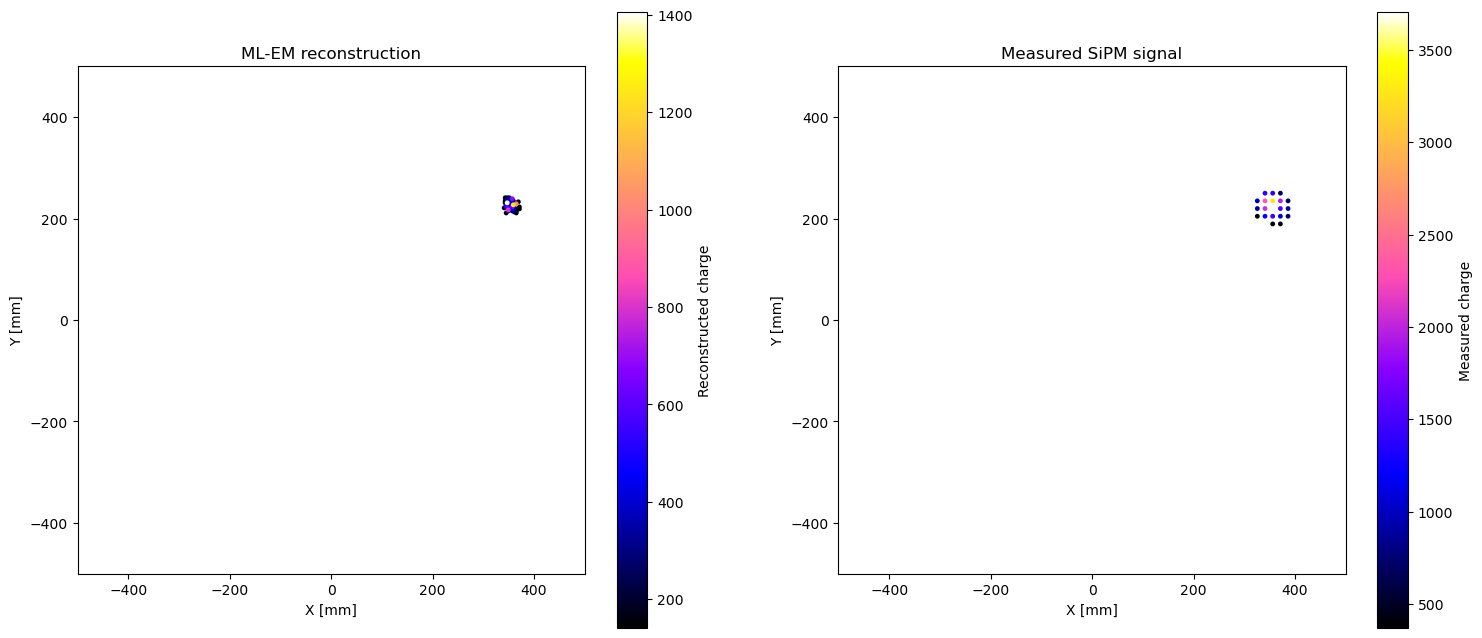

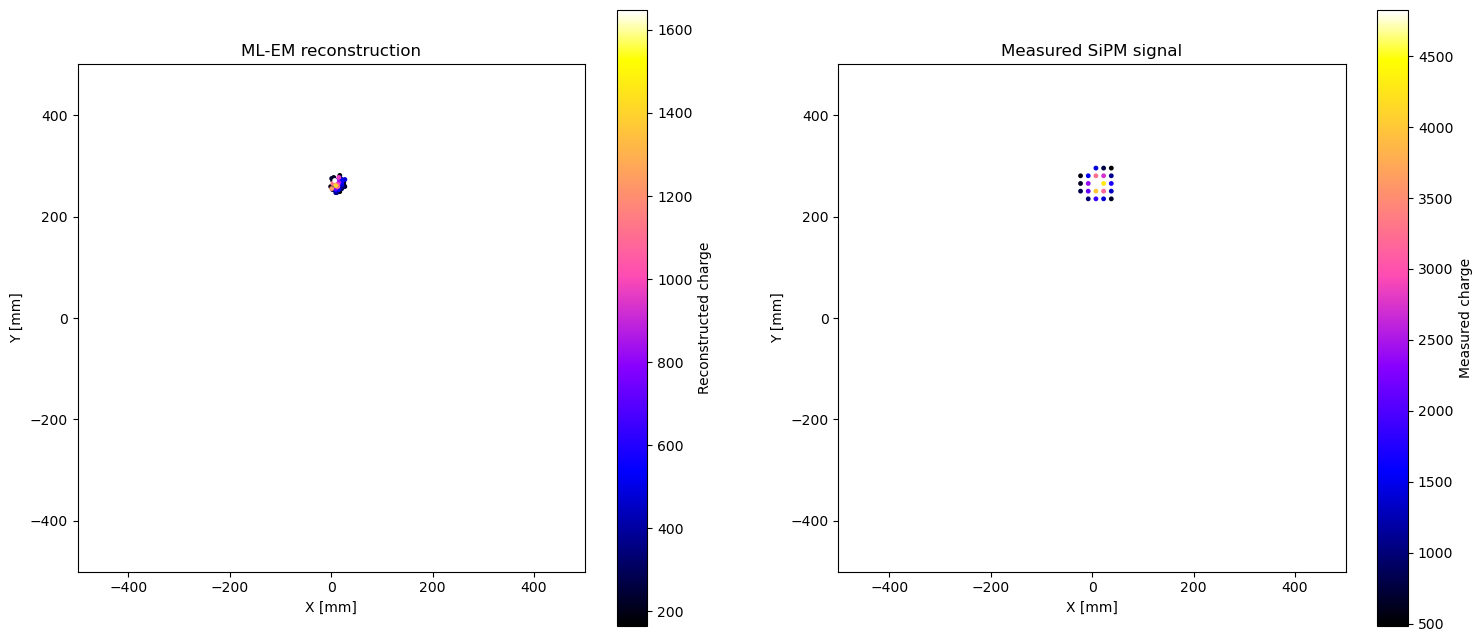

In [7]:
for cluster in evt.cluster.unique():

    cluster = evt[evt.cluster == cluster]

    H, xedges, yedges = np.histogram2d(cluster["X"], cluster["Y"], bins=66, weights=cluster["E"] / cluster["E"].sum(), range = ((-500, 500), (-500, 500)))

    centers_x = (xedges[:-1] + xedges[1:]) / 2
    centers_y = (yedges[:-1] + yedges[1:]) / 2

    y = H.ravel()
    zs = np.arange(0, 1400, 100)
    z0 = np.mean(cluster["Z"])

    idx = np.argmin(np.abs(zs - z0))

    path_sensor_response_by_bin, path_bin_x, path_bin_y, path_bin_ids, path_n_electrons_by_bin = find_path_files(idx)
    sensor_response_by_bin = np.load(path_sensor_response_by_bin)

    print("Sensor response loaded!!")

    initial_probability_distribution = np.ones(np.shape(sensor_response_by_bin)[0]) /np.shape(sensor_response_by_bin)[0]

    ml_em = ML_EM(initial_probability_distribution, y, sensor_response_by_bin, cluster, iterations = 30) 

    plot_deconvolved(ml_em, y*cluster.E.sum(), centers_x, centers_y, path_bin_x, path_bin_y)
